## Supplementary figures

## Figure S1 - DIC distribution from GOBAI-O2 2.3 (post-CONTENT)

In [21]:
import xarray as xr

# Load dataset with appropriate chunks
ds = xr.open_dataset('data/CONTENT_DIC_v2-3.nc')

# Only keep data down to 1000m
ds = ds.where(ds.pres <= 1000, drop=True)

# Only keep variable of interest
# ds = ds[['CT']]

In [22]:
ds

<xarray.Dataset> Size: 19GB
Dimensions:       (time: 252, pres: 44, lat: 145, lon: 360)
Coordinates:
  * time          (time) datetime64[ns] 2kB 2004-01-16 2004-02-16 ... 2024-12-16
  * pres          (pres) float32 176B 2.5 10.0 20.0 30.0 ... 900.0 950.0 1e+03
  * lat           (lat) float32 580B -64.5 -63.5 -62.5 -61.5 ... 77.5 78.5 79.5
  * lon           (lon) float32 1kB 20.5 21.5 22.5 23.5 ... 377.5 378.5 379.5
Data variables:
    o2            (time, pres, lat, lon) float32 2GB 352.1 352.2 ... nan nan
    uncer         (time, pres, lat, lon) float32 2GB 12.2 12.32 ... nan nan
    temp          (time, pres, lat, lon) float32 2GB -0.033 -0.045 ... nan nan
    sal           (time, pres, lat, lon) float32 2GB 33.75 33.74 ... nan nan
    oxy           (time, lon, lat, pres) float32 2GB 352.1 352.6 ... nan nan
    CT            (time, lon, lat, pres) float32 2GB 2.156e+03 2.157e+03 ... nan
    CT_sigma      (time, lon, lat, pres) float32 2GB 12.21 12.13 ... nan nan
    CT_sigma_min  (time, lon, lat, pres) float32 2GB 9.455 9.372 ... nan nan

# 4 - Plot DIC at surface, 300m, 500m and 1000m

In [23]:
surface = ds['CT'].mean(dim='time').isel(pres=1)
middepth = ds['CT'].mean(dim='time').isel(pres=24)
middeep = ds['CT'].mean(dim='time').isel(pres=33)
deep = ds['CT'].mean(dim='time').isel(pres=43)

In [24]:
surface = surface.transpose()
middepth = middepth.transpose()
middeep = middeep.transpose()
deep = deep.transpose()

In [25]:
import numpy as np

# Define a Mediterranean mask function
def mask_mediterranean(data):
    lat = data.lat
    lon = data.lon

    # Adjust longitudes if necessary (0 to 360 → -180 to 180)
    lon_corrected = lon.where(lon <= 180, lon - 360)

    # Mediterranean bounding box (rough estimate)
    med_mask = ((lat > 30) & (lat < 46)) & ((lon_corrected > -6) & (lon_corrected < 37))

    # Apply mask to data
    data = data.where(~med_mask, np.nan)
    return data

# Apply mask to each dataset
surface = mask_mediterranean(surface)
middepth = mask_mediterranean(middepth)
middeep = mask_mediterranean(middeep)
deep = mask_mediterranean(deep)


/tmp/ipykernel_4073006/3124871179.py:75: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


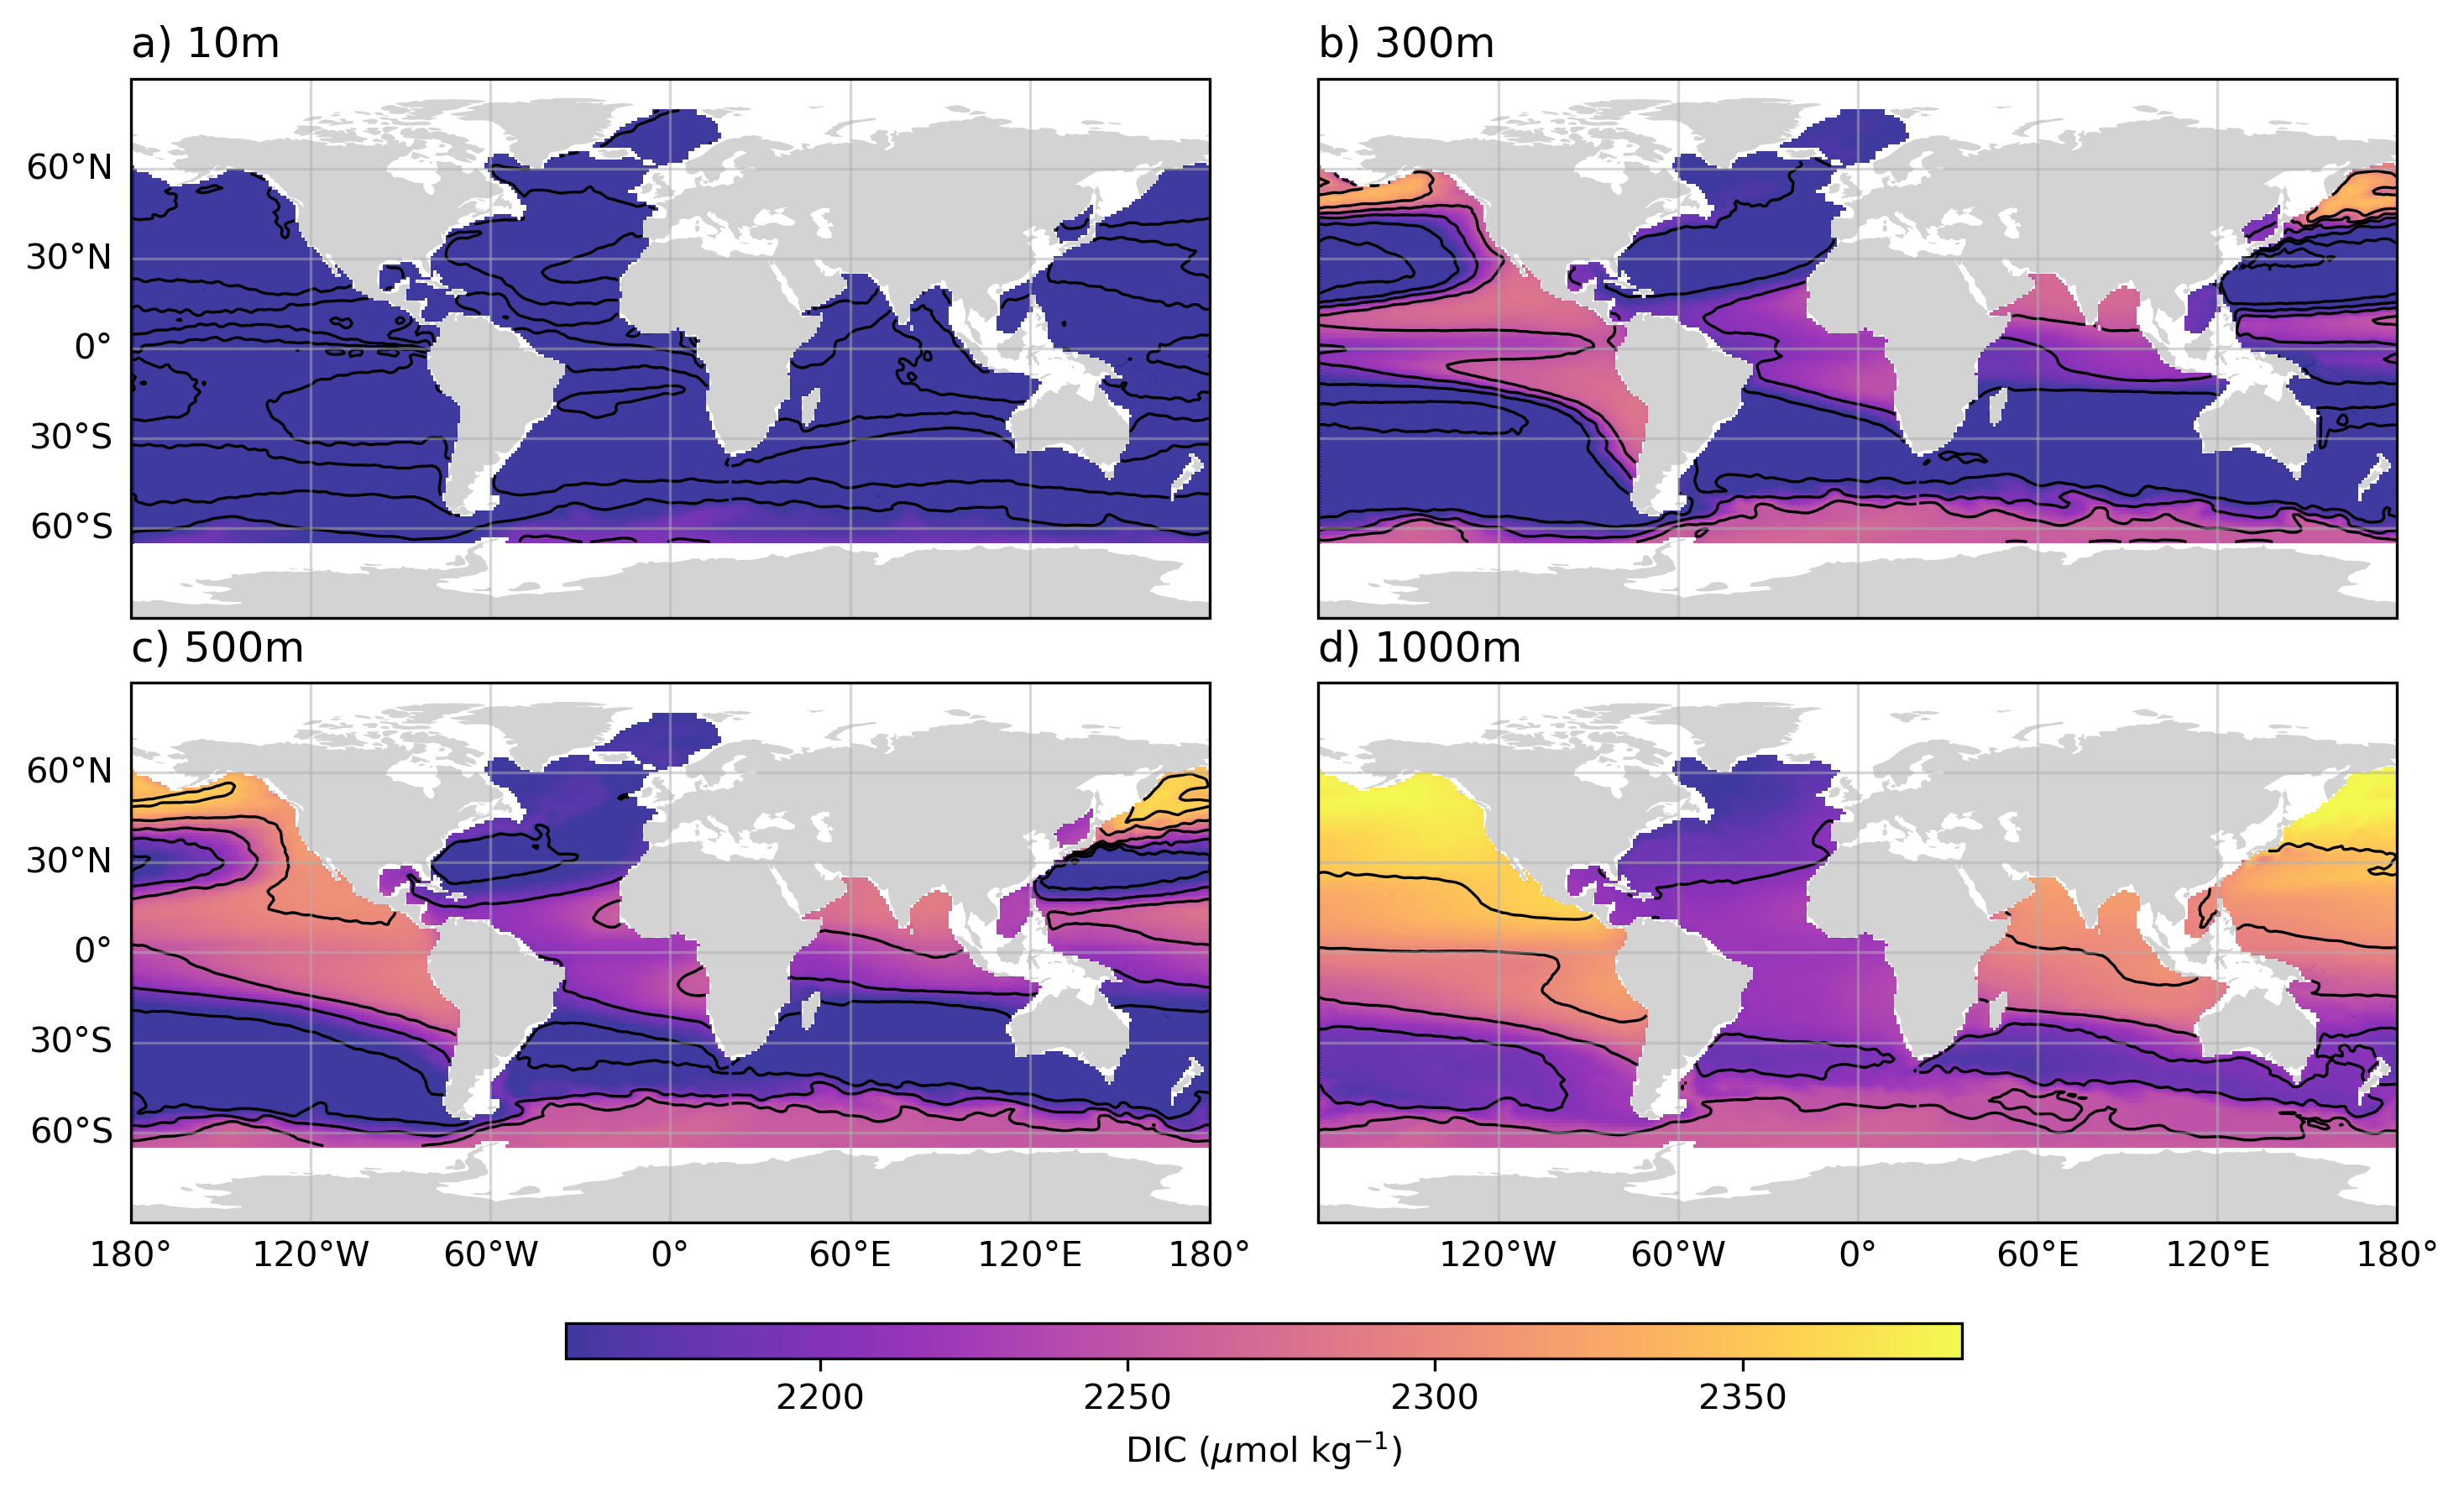

In [26]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import ListedColormap
from matplotlib.colors import BoundaryNorm
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.colors import Normalize

# Create figure
fig, axs = plt.subplots(2, 2, figsize=(10, 6), dpi=300, subplot_kw={'projection': ccrs.PlateCarree()})

# Contour levels every 50 μmol kg⁻¹
contour_levels = list(range(0, int(max(surface.max(), middepth.max(), middeep.max(), deep.max())) + 50, 50))

# Find the overall maximum value across all datasets
min_value = max(
    surface.min().compute().item(),
    middepth.min().compute().item(),
    middeep.min().compute().item(),
    deep.min().compute().item()
)
max_value = max(
    surface.max().compute().item(),
    middepth.max().compute().item(),
    middeep.max().compute().item(),
    deep.max().compute().item()
)

# Create a normalization object with a range of 0 to the overall maximum
norm = Normalize(vmin=min_value, vmax=max_value)

# Add different depths distributions with the same normalization
pcolormesh_plots = [
    axs[0, 0].pcolormesh(surface.lon, surface.lat, surface, cmap='plasma', alpha=0.8, transform=ccrs.PlateCarree(), norm=norm),
    axs[0, 1].pcolormesh(middepth.lon, middepth.lat, middepth, cmap='plasma', alpha=0.8, transform=ccrs.PlateCarree(), norm=norm),
    axs[1, 0].pcolormesh(middeep.lon, middeep.lat, middeep, cmap='plasma', alpha=0.8, transform=ccrs.PlateCarree(), norm=norm),
    axs[1, 1].pcolormesh(deep.lon, deep.lat, deep, cmap='plasma', alpha=0.8, transform=ccrs.PlateCarree(), norm=norm),
]

# Add features and contours to all subplots
subplot_labels = ['a) 10m', 'b) 300m', 'c) 500m', 'd) 1000m']
data_sets = [surface, middepth, middeep, deep]

for ax, label, data, row, col in zip(axs.flat, subplot_labels, data_sets, [0, 0, 1, 1], [0, 1, 0, 1]):
    ax.add_feature(cfeature.LAND, edgecolor='none', facecolor='lightgrey')
    ax.set_ylim(-90, 90)

    # Add contour lines
    ax.contour(data.lon, data.lat, data, levels=contour_levels, colors='black', linewidths=0.8, transform=ccrs.PlateCarree())

    # Improve grid
    gl = ax.gridlines(draw_labels=True, alpha=0.5)
    gl.top_labels = False
    gl.right_labels = False
    gl.left_labels = (col == 0)
    gl.bottom_labels = (row == 1)

    # Add text to the upper left corner of each subplot
    ax.text(0., 1.1, label, transform=ax.transAxes, fontsize=12, verticalalignment='top')

# Create a common colorbar
cbar = fig.colorbar(
    pcolormesh_plots[0],
    ax=axs,
    orientation='horizontal',
    fraction=0.03,
    pad=0.1,
    aspect=40,
)

cbar.set_label(r'DIC ($\mu$mol kg$^{-1}$)')

plt.tight_layout()
# plt.subplots_adjust(hspace=0.1, wspace=0.1)
# Adjust layout to create more space at the bottom
plt.subplots_adjust(bottom=0.2)
plt.savefig('figs/S1_DIC_distrib.png', bbox_inches='tight', dpi=300)
plt.show()



# 5 - Plot TA at surface, 300m, 500m and 1000m

In [28]:
# Load dataset with appropriate chunks
ds = xr.open_dataset('data/CONTENT_AT_v2-3.nc')

# Only keep data down to 1000m
ds = ds.where(ds.pres <= 1000, drop=True)

# Only keep variable of interest
# ds = ds[['CT']]

In [29]:
surface = ds['AT'].mean(dim='time').isel(pres=1)
middepth = ds['AT'].mean(dim='time').isel(pres=24)
middeep = ds['AT'].mean(dim='time').isel(pres=33)
deep = ds['AT'].mean(dim='time').isel(pres=43)

In [30]:
surface = surface.transpose()
middepth = middepth.transpose()
middeep = middeep.transpose()
deep = deep.transpose()

In [31]:
# Define a Mediterranean mask function
def mask_mediterranean(data):
    lat = data.lat
    lon = data.lon

    # Adjust longitudes if necessary (0 to 360 → -180 to 180)
    lon_corrected = lon.where(lon <= 180, lon - 360)

    # Mediterranean bounding box (rough estimate)
    med_mask = ((lat > 30) & (lat < 46)) & ((lon_corrected > -6) & (lon_corrected < 37))

    # Apply mask to data
    data = data.where(~med_mask, np.nan)
    return data

# Apply mask to each dataset
surface = mask_mediterranean(surface)
middepth = mask_mediterranean(middepth)
middeep = mask_mediterranean(middeep)
deep = mask_mediterranean(deep)


/tmp/ipykernel_4073006/1568014405.py:65: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


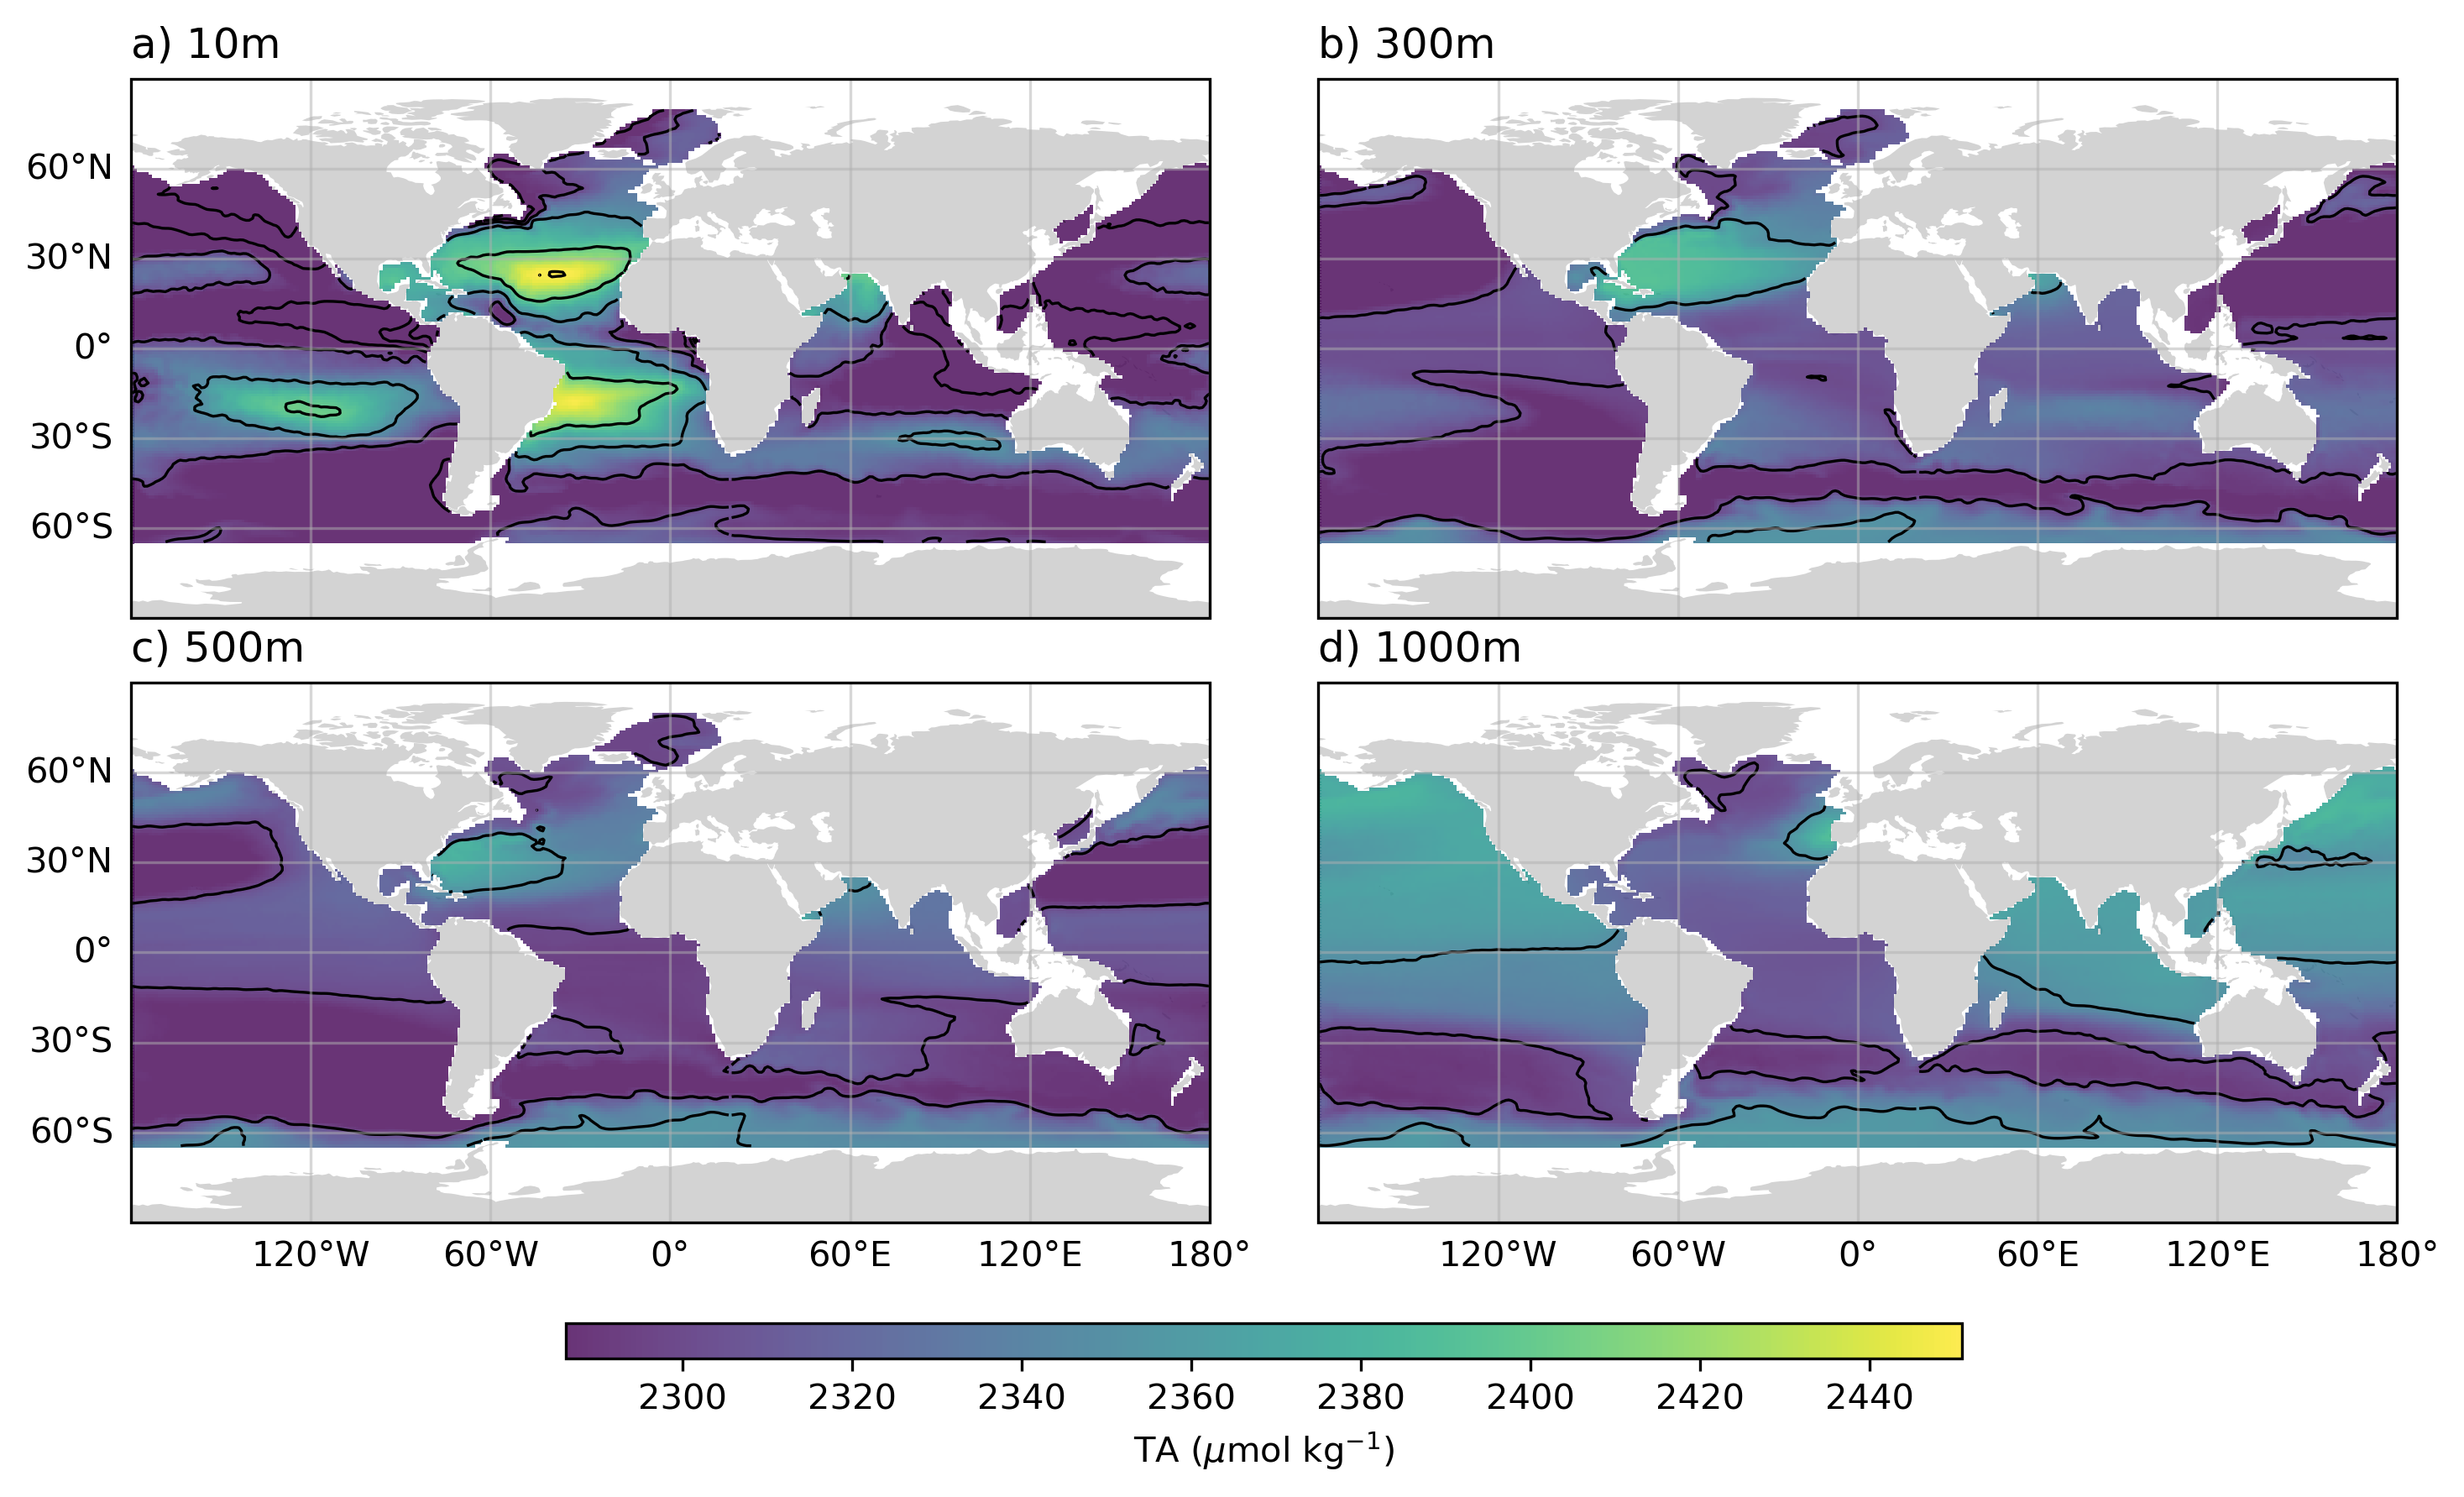

In [32]:
# Create figure
fig, axs = plt.subplots(2, 2, figsize=(10, 6), dpi=300, subplot_kw={'projection': ccrs.PlateCarree()})

# Contour levels every 50 μmol kg⁻¹
contour_levels = list(range(0, int(max(surface.max(), middepth.max(), middeep.max(), deep.max())) + 50, 50))

# Find the overall maximum value across all datasets
min_value = max(
    surface.min().compute().item(),
    middepth.min().compute().item(),
    middeep.min().compute().item(),
    deep.min().compute().item()
)
max_value = max(
    surface.max().compute().item(),
    middepth.max().compute().item(),
    middeep.max().compute().item(),
    deep.max().compute().item()
)

# Create a normalization object with a range of 0 to the overall maximum
norm = Normalize(vmin=min_value, vmax=max_value)

# Add different depths distributions with the same normalization
pcolormesh_plots = [
    axs[0, 0].pcolormesh(surface.lon, surface.lat, surface, cmap='viridis', alpha=0.8, transform=ccrs.PlateCarree(), norm=norm),
    axs[0, 1].pcolormesh(middepth.lon, middepth.lat, middepth, cmap='viridis', alpha=0.8, transform=ccrs.PlateCarree(), norm=norm),
    axs[1, 0].pcolormesh(middeep.lon, middeep.lat, middeep, cmap='viridis', alpha=0.8, transform=ccrs.PlateCarree(), norm=norm),
    axs[1, 1].pcolormesh(deep.lon, deep.lat, deep, cmap='viridis', alpha=0.8, transform=ccrs.PlateCarree(), norm=norm),
]

# Add features and contours to all subplots
subplot_labels = ['a) 10m', 'b) 300m', 'c) 500m', 'd) 1000m']
data_sets = [surface, middepth, middeep, deep]

for ax, label, data, row, col in zip(axs.flat, subplot_labels, data_sets, [0, 0, 1, 1], [0, 1, 0, 1]):
    ax.add_feature(cfeature.LAND, edgecolor='none', facecolor='lightgrey')
    ax.set_ylim(-90, 90)

    # Add contour lines
    ax.contour(data.lon, data.lat, data, levels=contour_levels, colors='black', linewidths=0.8, transform=ccrs.PlateCarree())

    # Improve grid
    gl = ax.gridlines(draw_labels=True, alpha=0.5)
    gl.top_labels = False
    gl.right_labels = False
    gl.left_labels = (col == 0)
    gl.bottom_labels = (row == 1)

    # Add text to the upper left corner of each subplot
    ax.text(0., 1.1, label, transform=ax.transAxes, fontsize=12, verticalalignment='top')

# Create a common colorbar
cbar = fig.colorbar(
    pcolormesh_plots[0],
    ax=axs,
    orientation='horizontal',
    fraction=0.03,
    pad=0.1,
    aspect=40,
)

cbar.set_label(r'TA ($\mu$mol kg$^{-1}$)')

plt.tight_layout()
# plt.subplots_adjust(hspace=0.1, wspace=0.1)
# Adjust layout to create more space at the bottom
plt.subplots_adjust(bottom=0.2)

plt.savefig('figs/S2_TA_distrib.png', bbox_inches='tight', dpi=300)
plt.show()

